# 1MD049 Task 1: DINOv3 for depth and real-time object distance estimation

Pipeline: **single RGB image/video -> depth -> back-project to 3D -> distance between objects**.

What this notebook does
1. Benchmarks depth estimation on NYU Depth v2 (test = the standard 654 images).
2. Trains a small depth head on a **frozen DINOv3** backbone and compares it with the **same head on DINOv2** (controlled comparison), with Depth Anything 3 (DINOv2-based) and with a classic UNet.
3. Measures real distances in **your own room** against a tape measure.
4. Runs detection + depth on a video and draws object-to-object distances (FPS reported).
5. Drone case: size-based distance vs monocular depth.

In [ ]:
import os
os.environ["XFORMERS_DISABLED"] = "1"
os.environ["HF_HOME"] = "/proj/uppmax2026-1-299/fahim/hf_cache"
os.environ["TORCH_HOME"] = "/proj/uppmax2026-1-299/fahim/torch_cache"
os.makedirs(os.environ["HF_HOME"], exist_ok=True)
os.makedirs(os.environ["TORCH_HOME"], exist_ok=True)

import time, math, json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import login, get_token

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
if device == "cuda":
    torch.cuda.manual_seed_all(0)

# Only prompt for token if not already cached in HF_HOME
if not get_token():
    login()  # DINOv3 repos are gated: needs a token with access

cuda NVIDIA H100 NVL


## 1. Data (NYU Depth v2)
`sayakpaul/nyu_depth_v2` on the Hugging Face Hub: 654 validation images (= the standard NYU test set) and a very large train split.
We stream only a small shuffled subset of train. **Never train on the 654 validation images.**

In [ ]:
from datasets import load_dataset

def load_nyu(split, streaming=False):
    # Dataset scripts may be disabled in new `datasets` versions -> try the parquet conversion as fallback
    for kw in [dict(), dict(revision="refs/convert/parquet")]:
        try:
            return load_dataset("sayakpaul/nyu_depth_v2", split=split, streaming=streaming, **kw)
        except Exception as e:
            print("load failed with", kw, "->", str(e)[:200])
    raise RuntimeError("Could not load NYU; find another NYU Depth v2 copy on the Hub or use the official .mat file")

# val_ds = load_nyu("validation")
# a = np.array(val_ds[0]["depth_map"]); print("depth_map dtype/min/max:", a.dtype, a.min(), a.max(), "mode:", val_ds[0]["depth_map"].mode)

In [ ]:
from datasets import load_dataset
import numpy as np

# Load ONLY the validation split via parquet (takes ~5-10 seconds)
val_ds = load_dataset(
    "sayakpaul/nyu_depth_v2",
    split="validation",
    revision="refs/convert/parquet"
)

print("Loaded validation samples:", len(val_ds))
a = np.array(val_ds[0]["depth_map"])
print("depth_map dtype/min/max:", a.dtype, a.min(), a.max(), "mode:", val_ds[0]["depth_map"].mode)

Loaded validation samples: 654
depth_map dtype/min/max: float32 1.7985953 3.615639 mode: F


In [ ]:
# # IMPORTANT: the depth maps on this dataset may be 8-bit (mode "L"). The mapping to metres is an ASSUMPTION
# # (0..255 -> 0..DEPTH_MAX_M). Check the printed min/max above. All "median"-aligned metrics are independent of this;
# # absolute-metre claims should only come from YOUR tape-measure experiment (section 5).
# DEPTH_MAX_M = 10.0

# def depth_from_pil(dm):
#     arr = np.array(dm)
#     a = arr.astype(np.float32)
#     if arr.dtype == np.uint8:
#         a = a / 255.0 * DEPTH_MAX_M
#     return a

# val_items = [(s["image"].convert("RGB"), s["depth_map"]) for s in tqdm(val_ds, desc="val")]

# N_TRAIN = 2000
# train_stream = load_nyu("train", streaming=True).shuffle(seed=0, buffer_size=2000)
# train_items = [(s["image"].convert("RGB"), s["depth_map"]) for s in tqdm(train_stream.take(N_TRAIN), total=N_TRAIN, desc="train subset")]
# print(len(train_items), len(val_items))

val:   0%|          | 0/654 [00:00<?, ?it/s]

train subset:   0%|          | 0/2000 [00:00<?, ?it/s]

2000 654


In [ ]:
CACHE_FILE = "nyu_subset_cache.pt"

if os.path.exists(CACHE_FILE):
    data = torch.load(CACHE_FILE, weights_only=False)
    train_items, val_items = data["train"], data["val"]
    print(f"Loaded from cache: {len(train_items)} train, {len(val_items)} val")
else:
    val_items = [(s["image"].convert("RGB"), s["depth_map"]) for s in tqdm(val_ds, desc="val")]
    N_TRAIN = 2000
    train_stream = load_nyu("train", streaming=True).shuffle(seed=0, buffer_size=500)
    train_items = [(s["image"].convert("RGB"), s["depth_map"]) for s in tqdm(train_stream.take(N_TRAIN), total=N_TRAIN, desc="train subset")]
    torch.save({"train": train_items, "val": val_items}, CACHE_FILE)
    print(f"Saved cache to {CACHE_FILE}")

val:   0%|          | 0/654 [00:00<?, ?it/s]

train subset:   0%|          | 0/2000 [00:00<?, ?it/s]

Saved cache to nyu_subset_cache.pt


## 2. Metrics and evaluation helper
* **AbsRel**, **RMSE**, **delta1** (fraction with max(p/g, g/p) < 1.25), the standard depth metrics.
* `median` alignment rescales each prediction to the GT median (fair for relative-depth models). `none` = raw metres.

In [ ]:
def compute_metrics(pred, gt, align="median", dmin=0.1, dmax=10.0):
    m = (gt > dmin) & (gt < dmax) & np.isfinite(pred)
    p, g = pred[m].astype(np.float64), gt[m].astype(np.float64)
    if align == "median":
        p = p * (np.median(g) / max(np.median(p), 1e-6))
    elif align == "lsq":
        A = np.stack([p, np.ones_like(p)], 1); s, t = np.linalg.lstsq(A, g, rcond=None)[0]; p = s * p + t
    p = np.clip(p, 1e-3, None)
    return np.mean(np.abs(p - g) / g), np.sqrt(np.mean((p - g) ** 2)), np.mean(np.maximum(p / g, g / p) < 1.25)

def evaluate(name, predict_fn, items, bs=8, aligns=("median", "none")):
    preds, t = [], 0.0
    for i in tqdm(range(0, len(items), bs), desc=name):
        imgs = [x[0] for x in items[i:i + bs]]
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time(); out = predict_fn(imgs)
        if device == "cuda": torch.cuda.synchronize()
        t += time.time() - t0; preds += out
    rows = []
    for al in aligns:
        r = np.array([compute_metrics(p, depth_from_pil(x[1]), al) for p, x in zip(preds, items)])
        rows.append(dict(model=name, align=al, absrel=r[:, 0].mean(), rmse=r[:, 1].mean(), d1=r[:, 2].mean(),
                         ms_per_img=1000 * t / len(items)))
    return rows

RESULTS = []

## 3. DINOv3 (and DINOv2) backbone + light depth head
The backbone is **frozen** (set `train_blocks>0` to also fine-tune the last blocks). We take 4 intermediate layers, drop CLS/register tokens,
fuse them and upsample to full resolution. Same head for DINOv2 and DINOv3 -> a controlled comparison of the *features*.

In [ ]:
from transformers import AutoModel

BACKBONES = {
    "dinov3-vits16": "facebook/dinov3-vits16-pretrain-lvd1689m",
    "dinov3-vitb16": "facebook/dinov3-vitb16-pretrain-lvd1689m",
    "dinov2-small":  "facebook/dinov2-small",
    "dinov2-base":   "facebook/dinov2-base",
}
IN_H, IN_W = 336, 448          # divisible by both 16 (DINOv3) and 14 (DINOv2)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

class DinoDepth(nn.Module):
    def __init__(self, key="dinov3-vits16", ch=128, train_blocks=0):
        super().__init__()
        self.bb = AutoModel.from_pretrained(BACKBONES[key])
        cfg = self.bb.config
        self.patch = cfg.patch_size if isinstance(cfg.patch_size, int) else cfg.patch_size[0]
        self.n_reg = getattr(cfg, "num_register_tokens", 0)
        L, D = cfg.num_hidden_layers, cfg.hidden_size
        self.layers = [L // 4, L // 2, 3 * L // 4, L]
        for p in self.bb.parameters(): p.requires_grad = False
        self.ft = train_blocks > 0
        if self.ft:
            blocks = getattr(self.bb, "layer", None) or self.bb.encoder.layer
            for b in blocks[-train_blocks:]:
                for p in b.parameters(): p.requires_grad = True
        self.proj = nn.ModuleList([nn.Sequential(nn.Conv2d(D, ch, 1), nn.GroupNorm(8, ch), nn.GELU()) for _ in self.layers])
        self.fuse = nn.Sequential(nn.Conv2d(ch * 4, ch * 2, 3, padding=1), nn.GroupNorm(8, ch * 2), nn.GELU(),
                                  nn.Conv2d(ch * 2, ch * 2, 3, padding=1), nn.GELU())
        self.up = nn.Sequential(nn.Conv2d(ch * 2, ch, 3, padding=1), nn.GELU())
        self.out = nn.Sequential(nn.Conv2d(ch, ch // 2, 3, padding=1), nn.GELU(), nn.Conv2d(ch // 2, 1, 1))

    def forward(self, x):
        B, _, H, W = x.shape
        h, w = H // self.patch, W // self.patch
        with torch.set_grad_enabled(self.ft and self.training):
            hs = self.bb(pixel_values=x, output_hidden_states=True).hidden_states
        feats = []
        for pr, i in zip(self.proj, self.layers):
            t = hs[i][:, 1 + self.n_reg:, :]                         # drop CLS (+ register tokens)
            feats.append(pr(t.transpose(1, 2).reshape(B, -1, h, w)))
        y = self.fuse(torch.cat(feats, 1))
        y = self.up(F.interpolate(y, scale_factor=2, mode="bilinear", align_corners=False))
        y = F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)
        return F.softplus(self.out(y)).squeeze(1)                      # positive depth map

def prep(imgs):
    x = torch.stack([torch.from_numpy(np.array(i.resize((IN_W, IN_H), Image.BILINEAR))).permute(2, 0, 1) for i in imgs]).float() / 255
    return (x - MEAN) / STD

@torch.no_grad()
def predict_torch(model, imgs):
    model.eval()
    x = prep(imgs).to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
        d = model(x)
    d = d.float().unsqueeze(1)
    return [F.interpolate(d[i:i + 1], size=(im.size[1], im.size[0]), mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
            for i, im in enumerate(imgs)]

In [ ]:
DEPTH_MAX_M = 10.0

def depth_from_pil(dm):
    arr = np.array(dm)
    a = arr.astype(np.float32)
    if arr.dtype == np.uint8:
        a = a / 255.0 * DEPTH_MAX_M
    return a

class DepthDS(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        im, dm = self.items[i]
        img = im.resize((IN_W, IN_H), Image.BILINEAR)
        dep = Image.fromarray(depth_from_pil(dm)).resize((IN_W, IN_H), Image.NEAREST)
        x = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255
        y = torch.from_numpy(np.array(dep)).float()
        if random.random() < 0.5: x, y = x.flip(-1), y.flip(-1)
        x = (x * (0.8 + 0.4 * random.random())).clamp(0, 1)
        return (x - MEAN[0]) / STD[0], y

def silog(pred, gt, lam=0.5):
    m = gt > 0.1
    d = torch.log(pred[m].clamp(min=1e-3)) - torch.log(gt[m])
    return 10 * torch.sqrt((d ** 2).mean() - lam * d.mean() ** 2 + 1e-8)   # lam<1 keeps some absolute-scale signal

def train_model(model, items, epochs=20, bs=8, lr=5e-4, lr_bb=1e-5):
    model.to(device).train()
    dl = DataLoader(DepthDS(items), batch_size=bs, shuffle=True, num_workers=4, drop_last=True)
    head = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("bb.")]
    bbp = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("bb.")]
    groups = [dict(params=head, lr=lr)] + ([dict(params=bbp, lr=lr_bb)] if bbp else [])
    opt = torch.optim.AdamW(groups, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], total_steps=epochs * len(dl))
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    for ep in range(epochs):
        model.train(); run = 0
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast("cuda", dtype=torch.float16, enabled=device == "cuda"):
                p = model(x)
            loss = silog(p.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            old_scale = scaler.get_scale()
            scaler.step(opt)
            scaler.update()
            if scaler.get_scale() >= old_scale:
                sched.step()
            run += loss.item()
        print(f"epoch {ep + 1}/{epochs}  loss {run / len(dl):.4f}")
    return model

MODELS = {}
for key in ["dinov3-vits16", "dinov2-small", "dinov3-vitb16", "dinov2-base"]:          # add "dinov3-vitb16", "dinov2-base" when time allows
    m = DinoDepth(key)
    MODELS[key] = train_model(m, train_items)
    torch.save({k: v for k, v in m.state_dict().items() if not k.startswith("bb.")}, f"head_{key}.pt")
    RESULTS = [r for r in RESULTS if r["model"] != f"{key}+head"]
    RESULTS += evaluate(f"{key}+head", lambda imgs, mm=m: predict_torch(mm, imgs), val_items)
pd.DataFrame(RESULTS)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

epoch 1/20  loss 3.8231
epoch 2/20  loss 1.6079
epoch 3/20  loss 1.3755
epoch 4/20  loss 1.2487
epoch 5/20  loss 1.1485
epoch 6/20  loss 1.0986
epoch 7/20  loss 1.0106
epoch 8/20  loss 0.9344
epoch 9/20  loss 0.9006
epoch 10/20  loss 0.8470
epoch 11/20  loss 0.8121
epoch 12/20  loss 0.7703
epoch 13/20  loss 0.7440
epoch 14/20  loss 0.7080
epoch 15/20  loss 0.6866
epoch 16/20  loss 0.6598
epoch 17/20  loss 0.6390
epoch 18/20  loss 0.6226
epoch 19/20  loss 0.6123
epoch 20/20  loss 0.6082


dinov3-vits16+head:   0%|          | 0/82 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

epoch 1/20  loss 3.9304
epoch 2/20  loss 1.5592
epoch 3/20  loss 1.3373
epoch 4/20  loss 1.2223
epoch 5/20  loss 1.1455
epoch 6/20  loss 1.0556
epoch 7/20  loss 0.9915
epoch 8/20  loss 0.9415
epoch 9/20  loss 0.8716
epoch 10/20  loss 0.8456
epoch 11/20  loss 0.8015
epoch 12/20  loss 0.7567
epoch 13/20  loss 0.7213
epoch 14/20  loss 0.6930
epoch 15/20  loss 0.6656
epoch 16/20  loss 0.6403
epoch 17/20  loss 0.6202
epoch 18/20  loss 0.6045
epoch 19/20  loss 0.5955
epoch 20/20  loss 0.5899


dinov2-small+head:   0%|          | 0/82 [00:00<?, ?it/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

epoch 1/20  loss 3.7504
epoch 2/20  loss 1.4056
epoch 3/20  loss 1.2000
epoch 4/20  loss 1.0988
epoch 5/20  loss 1.0396
epoch 6/20  loss 0.9727
epoch 7/20  loss 0.8873
epoch 8/20  loss 0.8493
epoch 9/20  loss 0.7917
epoch 10/20  loss 0.7666
epoch 11/20  loss 0.7157
epoch 12/20  loss 0.6843
epoch 13/20  loss 0.6587
epoch 14/20  loss 0.6335
epoch 15/20  loss 0.6025
epoch 16/20  loss 0.5783
epoch 17/20  loss 0.5610
epoch 18/20  loss 0.5441
epoch 19/20  loss 0.5363
epoch 20/20  loss 0.5320


dinov2-base+head:   0%|          | 0/82 [00:00<?, ?it/s]

,model,align,absrel,rmse,d1,ms_per_img
0,dinov3-vits16+head,median,0.142189,0.518587,0.810665,9.823585
1,dinov3-vits16+head,none,0.188235,0.605104,0.722649,9.823585
2,dinov2-small+head,median,0.127278,0.465617,0.844827,7.646478
3,dinov2-small+head,none,0.168198,0.548796,0.759225,7.646478
4,dinov3-vitb16+head,median,0.120741,0.450237,0.859581,4.690733
5,dinov3-vitb16+head,none,0.177290,0.562216,0.747724,4.690733
6,dinov2-base+head,median,0.110874,0.416870,0.879508,4.429125
7,dinov2-base+head,none,0.151096,0.495305,0.795274,4.429125


## 4. Baselines: UNet and Depth Anything 3
* The project text links a ~6-year-old UNet repo. The cell below trains a ResNet-34 **U-Net** under identical conditions (fair, same data/loss/resolution). If you also run the original repo, add its row to `RESULTS` for comparison.
* **Depth Anything 3** is built on DINOv2. Model ids follow the pattern on its GitHub page / Hub (e.g. `depth-anything/DA3METRIC-LARGE`, `depth-anything/DA3-SMALL`); check the model cards if a name fails.

In [ ]:
import torchvision
class UNetDepth(nn.Module):
    def __init__(self):
        super().__init__()
        r = torchvision.models.resnet34(weights="IMAGENET1K_V1")
        self.l0 = nn.Sequential(r.conv1, r.bn1, r.relu); self.pool = r.maxpool
        self.l1, self.l2, self.l3, self.l4 = r.layer1, r.layer2, r.layer3, r.layer4
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True),
                                            nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(True))
        self.d4, self.d3, self.d2, self.d1 = blk(512 + 256, 256), blk(256 + 128, 128), blk(128 + 64, 64), blk(64 + 64, 64)
        self.out = nn.Conv2d(64, 1, 3, padding=1)
    def forward(self, x):
        H, W = x.shape[-2:]
        x0 = self.l0(x); x1 = self.l1(self.pool(x0)); x2 = self.l2(x1); x3 = self.l3(x2); x4 = self.l4(x3)
        cat = lambda a, b: torch.cat([F.interpolate(a, size=b.shape[-2:], mode="bilinear", align_corners=False), b], 1)
        y = self.d4(cat(x4, x3)); y = self.d3(cat(y, x2)); y = self.d2(cat(y, x1)); y = self.d1(cat(y, x0))
        y = F.interpolate(y, size=(H, W), mode="bilinear", align_corners=False)
        return F.softplus(self.out(y)).squeeze(1)

unet = train_model(UNetDepth(), train_items, epochs=12, lr=3e-4)
MODELS["unet"] = unet
RESULTS = [r for r in RESULTS if r["model"] != "unet-resnet34"]
RESULTS += evaluate("unet-resnet34", lambda imgs: predict_torch(unet, imgs), val_items)

epoch 1/12  loss 8.5707
epoch 2/12  loss 2.3988
epoch 3/12  loss 1.5692
epoch 4/12  loss 1.3424
epoch 5/12  loss 1.1636
epoch 6/12  loss 1.0257
epoch 7/12  loss 0.9428
epoch 8/12  loss 0.8397
epoch 9/12  loss 0.7460
epoch 10/12  loss 0.6742
epoch 11/12  loss 0.6229
epoch 12/12  loss 0.6037


unet-resnet34:   0%|          | 0/82 [00:00<?, ?it/s]

In [ ]:
torch.save(MODELS["unet"].state_dict(), "unet_resnet34.pt")

In [ ]:
# import torch
# torch.jit.script = lambda fn=None, *args, **kwargs: (lambda f: f) if fn is None else fn

# from depth_anything_3.api import DepthAnything3

# def predict_da3(model, imgs, metric=False):
#     pred = model.inference(list(imgs))
#     d = torch.from_numpy(np.asarray(pred.depth)).float()[:, None]
#     if metric:
#         f = torch.from_numpy(np.asarray(pred.intrinsics))[:, 0, 0].float().view(-1, 1, 1, 1)
#         d = d * f / 300.0
#     return [F.interpolate(d[i:i + 1], size=(im.size[1], im.size[0]), mode="bilinear", align_corners=False)[0, 0].numpy()
#             for i, im in enumerate(imgs)]

# for name, metric in [("depth-anything/DA3-SMALL", False), ("depth-anything/DA3METRIC-LARGE", True)]:
#     try:
#         da3 = DepthAnything3.from_pretrained(name).to(device)
#         short_name = name.split("/")[-1]
#         RESULTS = [r for r in RESULTS if r["model"] != short_name]
#         RESULTS += evaluate(short_name, lambda imgs, mm=da3, me=metric: predict_da3(mm, imgs, me), val_items, bs=4)
#         MODELS[name] = da3
#     except Exception as e:
#         print("failed", name, "->", e)

# df = pd.DataFrame(RESULTS).round(4)
# df.to_csv("nyu_results.csv", index=False)
# df

failed depth-anything/DA3-SMALL -> JITCallable._set_src() takes 1 positional argument but 2 were given
failed depth-anything/DA3METRIC-LARGE -> JITCallable._set_src() takes 1 positional argument but 2 were given


,model,align,absrel,rmse,d1,ms_per_img
0,dinov3-vits16+head,median,0.1422,0.5186,0.8107,9.8236
1,dinov3-vits16+head,none,0.1882,0.6051,0.7226,9.8236
2,dinov2-small+head,median,0.1273,0.4656,0.8448,7.6465
3,dinov2-small+head,none,0.1682,0.5488,0.7592,7.6465
4,dinov3-vitb16+head,median,0.1207,0.4502,0.8596,4.6907
5,dinov3-vitb16+head,none,0.1773,0.5622,0.7477,4.6907
6,dinov2-base+head,median,0.1109,0.4169,0.8795,4.4291
7,dinov2-base+head,none,0.1511,0.4953,0.7953,4.4291
8,unet-resnet34,median,0.2117,0.7608,0.6774,4.2129
9,unet-resnet34,none,0.2997,0.9028,0.5875,4.2129


In [ ]:
import sys

# Force depth_anything_3 to skip broken xformers/triton and use standard PyTorch fallback
sys.modules["xformers"] = None
sys.modules["xformers.ops"] = None
os.environ["DA3_LOG_LEVEL"] = "ERROR"

from depth_anything_3.api import DepthAnything3

def predict_da3(model, imgs, metric=False):
    pred = model.inference(list(imgs))
    d = torch.from_numpy(np.asarray(pred.depth)).float()[:, None]
    if metric:
        f = torch.from_numpy(np.asarray(pred.intrinsics))[:, 0, 0].float().view(-1, 1, 1, 1)
        d = d * f / 300.0
    return [F.interpolate(d[i:i + 1], size=(im.size[1], im.size[0]), mode="bilinear", align_corners=False)[0, 0].numpy()
            for i, im in enumerate(imgs)]

for name, metric in [("depth-anything/DA3-SMALL", False), ("depth-anything/DA3METRIC-LARGE", True)]:
    try:
        da3 = DepthAnything3.from_pretrained(name).to(device)
        short_name = name.split("/")[-1]
        RESULTS = [r for r in RESULTS if r["model"] != short_name]
        RESULTS += evaluate(short_name, lambda imgs, mm=da3, me=metric: predict_da3(mm, imgs, me), val_items, bs=4)
        MODELS[name] = da3
    except Exception as e:
        print("failed", name, "->", e)

df = pd.DataFrame(RESULTS).round(4)
df.to_csv("nyu_results.csv", index=False)
df

[INFO ] using MLP layer as FFN


DA3-SMALL:   0%|          | 0/164 [00:00<?, ?it/s]

[INFO ] Processed Images Done taking 0.012976646423339844 seconds. Shape:  torch.Size([4, 3, 378, 504])
[INFO ] Selecting reference view using strategy: saddle_balanced
[INFO ] Model Forward Pass Done. Time: 0.018769502639770508 seconds
[INFO ] Conversion to Prediction Done. Time: 0.00042629241943359375 seconds
[INFO ] Processed Images Done taking 0.013707637786865234 seconds. Shape:  torch.Size([4, 3, 378, 504])
[INFO ] Selecting reference view using strategy: saddle_balanced
[INFO ] Model Forward Pass Done. Time: 0.018556594848632812 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0004210472106933594 seconds
[INFO ] Processed Images Done taking 0.012111663818359375 seconds. Shape:  torch.Size([4, 3, 378, 504])
[INFO ] Selecting reference view using strategy: saddle_balanced
[INFO ] Model Forward Pass Done. Time: 0.018344640731811523 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0004334449768066406 seconds
[INFO ] Processed Images Done taking 0.01849055290222168 second

DA3METRIC-LARGE:   0%|          | 0/164 [00:00<?, ?it/s]

[INFO ] Processed Images Done taking 0.013585567474365234 seconds. Shape:  torch.Size([4, 3, 378, 504])
[INFO ] Model Forward Pass Done. Time: 0.02216315269470215 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0004966259002685547 seconds
failed depth-anything/DA3METRIC-LARGE -> can't convert np.ndarray of type numpy.object_. The only supported types are: float64, float32, float16, complex64, complex128, int64, int32, int16, int8, uint64, uint32, uint16, uint8, and bool.


,model,align,absrel,rmse,d1,ms_per_img
0,dinov3-vits16+head,median,0.1422,0.5186,0.8107,9.8236
1,dinov3-vits16+head,none,0.1882,0.6051,0.7226,9.8236
2,dinov2-small+head,median,0.1273,0.4656,0.8448,7.6465
3,dinov2-small+head,none,0.1682,0.5488,0.7592,7.6465
4,dinov3-vitb16+head,median,0.1207,0.4502,0.8596,4.6907
5,dinov3-vitb16+head,none,0.1773,0.5622,0.7477,4.6907
6,dinov2-base+head,median,0.1109,0.4169,0.8795,4.4291
7,dinov2-base+head,none,0.1511,0.4953,0.7953,4.4291
8,unet-resnet34,median,0.2117,0.7608,0.6774,4.2129
9,unet-resnet34,none,0.2997,0.9028,0.5875,4.2129


In [ ]:
import contextlib, io

def predict_da3(model, imgs, metric=False):
    with contextlib.redirect_stdout(io.StringIO()):
        pred = model.inference(list(imgs))
    d = torch.from_numpy(np.asarray(pred.depth, dtype=np.float32))[:, None]
    if metric:
        if pred.intrinsics is not None:
            f = torch.from_numpy(np.asarray(pred.intrinsics, dtype=np.float32))[:, 0, 0].view(-1, 1, 1, 1)
        else:
            # NYU Depth V2 focal length (~518px at 640w -> ~408px at DA3's 504w)
            f = 408.0
        d = d * f / 300.0
    return [F.interpolate(d[i:i + 1], size=(im.size[1], im.size[0]), mode="bilinear", align_corners=False)[0, 0].numpy()
            for i, im in enumerate(imgs)]

name = "depth-anything/DA3METRIC-LARGE"
da3 = DepthAnything3.from_pretrained(name).to(device)
short_name = name.split("/")[-1]
RESULTS = [r for r in RESULTS if r["model"] != short_name]
RESULTS += evaluate(short_name, lambda imgs, mm=da3: predict_da3(mm, imgs, metric=True), val_items, bs=4)
MODELS[name] = da3

df = pd.DataFrame(RESULTS).round(4)
df.to_csv("nyu_results.csv", index=False)
df

[INFO ] using MLP layer as FFN


DA3METRIC-LARGE:   0%|          | 0/164 [00:00<?, ?it/s]

,model,align,absrel,rmse,d1,ms_per_img
0,dinov3-vits16+head,median,0.1422,0.5186,0.8107,9.8236
1,dinov3-vits16+head,none,0.1882,0.6051,0.7226,9.8236
2,dinov2-small+head,median,0.1273,0.4656,0.8448,7.6465
3,dinov2-small+head,none,0.1682,0.5488,0.7592,7.6465
4,dinov3-vitb16+head,median,0.1207,0.4502,0.8596,4.6907
5,dinov3-vitb16+head,none,0.1773,0.5622,0.7477,4.6907
6,dinov2-base+head,median,0.1109,0.4169,0.8795,4.4291
7,dinov2-base+head,none,0.1511,0.4953,0.7953,4.4291
8,unet-resnet34,median,0.2117,0.7608,0.6774,4.2129
9,unet-resnet34,none,0.2997,0.9028,0.5875,4.2129


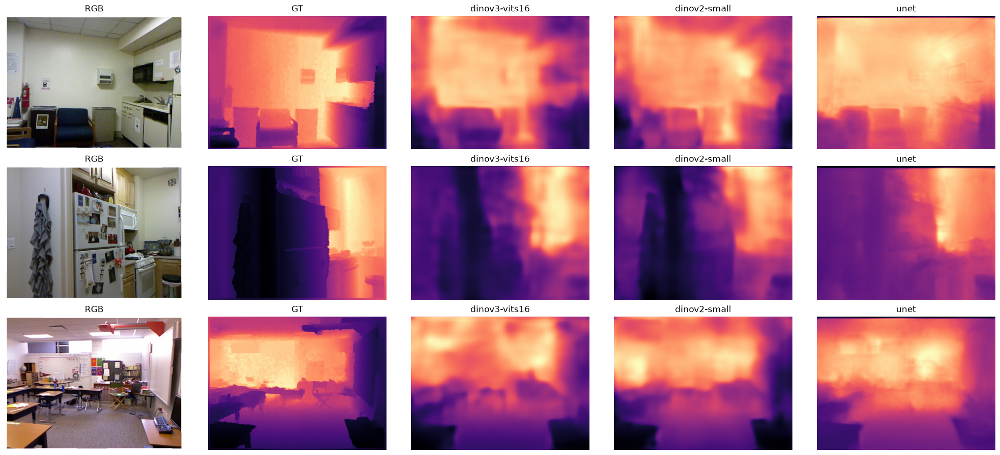

In [ ]:
# # Qualitative comparison on a few NYU test images
# idx = [0, 50, 120]
# names = [k for k in MODELS if k in ("dinov3-vits16", "dinov2-small", "unet")]
# fig, ax = plt.subplots(len(idx), 2 + len(names), figsize=(4 * (2 + len(names)), 3 * len(idx)))
# for r, i in enumerate(idx):
#     im, dm = val_items[i]
#     ax[r, 0].imshow(im); ax[r, 1].imshow(depth_from_pil(dm), cmap="magma"); ax[r, 0].set_title("RGB"); ax[r, 1].set_title("GT")
#     for c, n in enumerate(names):
#         ax[r, 2 + c].imshow(predict_torch(MODELS[n], [im])[0], cmap="magma"); ax[r, 2 + c].set_title(n)
# for a_ in ax.ravel(): a_.axis("off")
# plt.tight_layout(); plt.savefig("nyu_qualitative.png", dpi=150); plt.show()

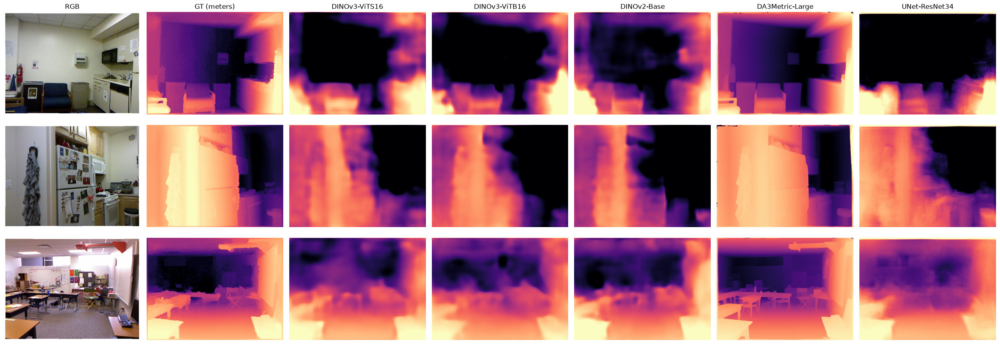

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

idx = [0, 50, 120]

# Order models from baseline -> ViT-S -> ViT-B -> DA3Metric-Large
candidates = [
    ("dinov3-vits16", "DINOv3-ViTS16"),
    ("dinov3-vitb16", "DINOv3-ViTB16"),
    ("dinov2-base", "DINOv2-Base"),
    ("depth-anything/DA3METRIC-LARGE", "DA3Metric-Large"),
    ("unet", "UNet-ResNet34"),
]
active = [(k, label) for k, label in candidates if k in MODELS]

fig, ax = plt.subplots(
    len(idx), 2 + len(active),
    figsize=(3.6 * (2 + len(active)), 3.0 * len(idx))
)

for r, i in enumerate(idx):
    im, dm = val_items[i]
    gt = depth_from_pil(dm)
    valid = gt > 0.1
    vmin, vmax = np.percentile(gt[valid], [2, 98])  # shared metric color range per row

    ax[r, 0].imshow(im)
    ax[r, 0].set_title("RGB" if r == 0 else "")

    im_gt = ax[r, 1].imshow(gt, cmap="magma_r", vmin=vmin, vmax=vmax)
    ax[r, 1].set_title("GT (meters)" if r == 0 else "")

    for c, (k, label) in enumerate(active):
        if "DA3" in k:
            pred = predict_da3(MODELS[k], [im], metric="METRIC" in k)[0]
        else:
            pred = predict_torch(MODELS[k], [im])[0]

        ax[r, 2 + c].imshow(pred, cmap="magma_r", vmin=vmin, vmax=vmax)
        ax[r, 2 + c].set_title(label if r == 0 else "")

for a_ in ax.ravel():
    a_.axis("off")

plt.tight_layout()
plt.savefig("nyu_qualitative.png", dpi=200, bbox_inches="tight")
plt.show()

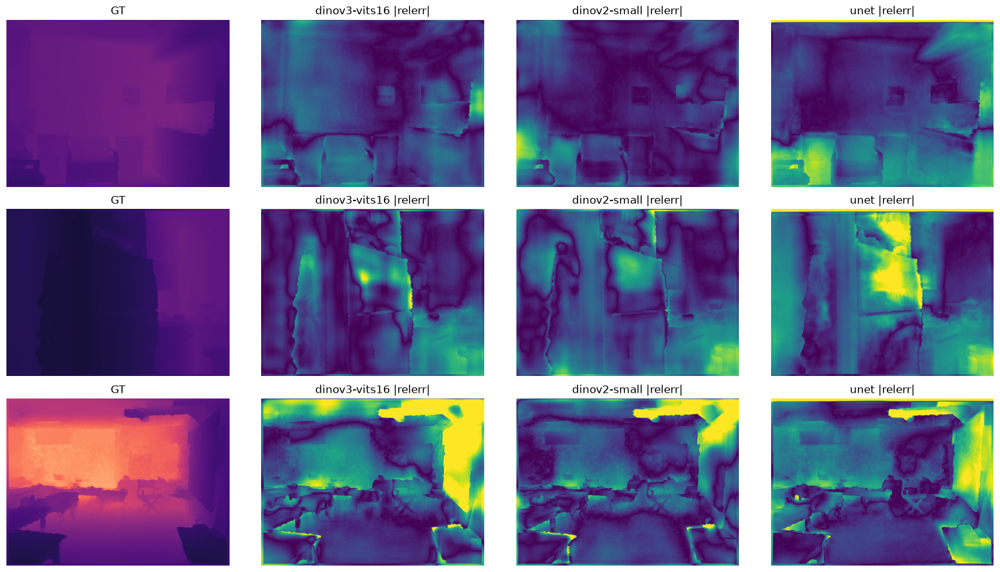

In [ ]:
# fig, ax = plt.subplots(len(idx), 1 + len(names), figsize=(4 * (1 + len(names)), 3 * len(idx)))
# for r, i in enumerate(idx):
#     im, dm = val_items[i]; gt = depth_from_pil(dm); ax[r, 0].imshow(gt, cmap="magma", vmin=0, vmax=10); ax[r, 0].set_title("GT")
#     for c, n in enumerate(names):
#         p = predict_torch(MODELS[n], [im])[0]; p = p * np.median(gt[gt > 0.1]) / np.median(p)   # median-aligned
#         e = np.abs(p - gt) / np.clip(gt, 0.1, None)
#         ax[r, 1 + c].imshow(e, cmap="viridis", vmin=0, vmax=0.5); ax[r, 1 + c].set_title(f"{n} |relerr|")
# for a_ in ax.ravel(): a_.axis("off")
# plt.tight_layout(); plt.savefig("nyu_errors.png", dpi=150); plt.show()

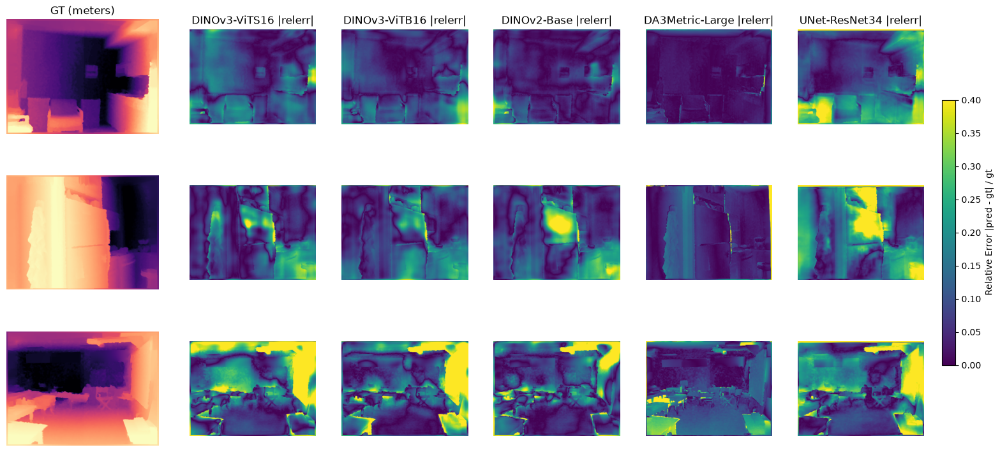

In [ ]:
idx = [0, 50, 120]
candidates = [
    ("dinov3-vits16", "DINOv3-ViTS16"),
    ("dinov3-vitb16", "DINOv3-ViTB16"),
    ("dinov2-base", "DINOv2-Base"),
    ("depth-anything/DA3METRIC-LARGE", "DA3Metric-Large"),
    ("unet", "UNet-ResNet34"),
]
active = [(k, label) for k, label in candidates if k in MODELS]

fig, ax = plt.subplots(
    len(idx), 1 + len(active),
    figsize=(3.6 * (1 + len(active)), 3.0 * len(idx))
)

for r, i in enumerate(idx):
    im, dm = val_items[i]
    gt = depth_from_pil(dm)
    valid = gt > 0.1
    vmin, vmax = np.percentile(gt[valid], [2, 98])

    ax[r, 0].imshow(gt, cmap="magma_r", vmin=vmin, vmax=vmax)
    ax[r, 0].set_title("GT (meters)" if r == 0 else "")

    for c, (k, label) in enumerate(active):
        p = predict_da3(MODELS[k], [im], metric="METRIC" in k)[0] if "DA3" in k else predict_torch(MODELS[k], [im])[0]
        p = p * np.median(gt[valid]) / np.median(p[valid])  # median-aligned

        e = np.zeros_like(gt)
        e[valid] = np.abs(p[valid] - gt[valid]) / gt[valid]

        im_err = ax[r, 1 + c].imshow(e, cmap="viridis", vmin=0, vmax=0.4)
        ax[r, 1 + c].set_title(f"{label} |relerr|" if r == 0 else "")

for a_ in ax.ravel():
    a_.axis("off")

cbar = fig.colorbar(im_err, ax=ax[:, 1:], shrink=0.6, pad=0.02, label="Relative Error |pred - gt| / gt")
plt.savefig("nyu_errors.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Real distances measurement in my room scenes (the accurate-measurement experiment)

/proj/uppmax2026-1-299/fahim/images/IMG_2761.jpg -> upright size (W, H): (4284, 5712)


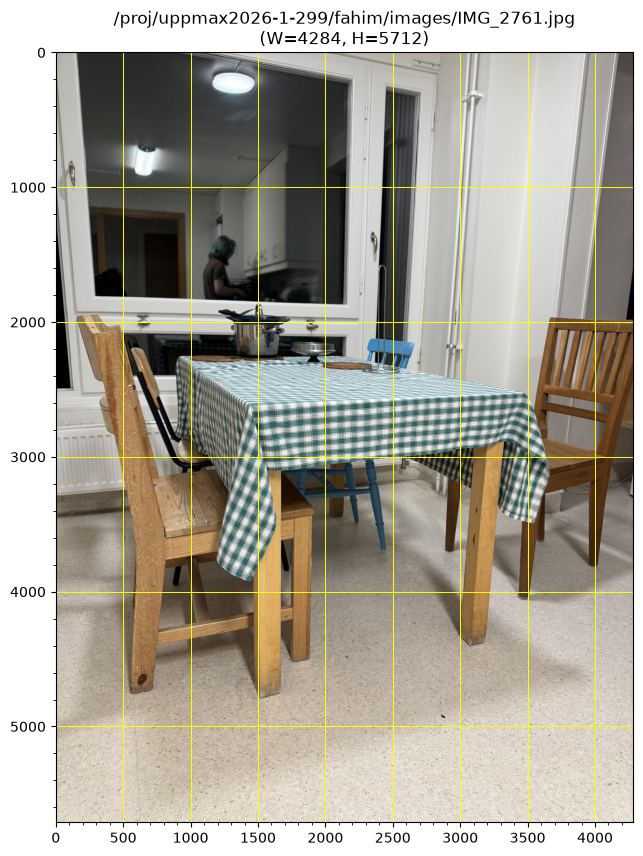

/proj/uppmax2026-1-299/fahim/images/IMG_2762.jpg -> upright size (W, H): (4284, 5712)


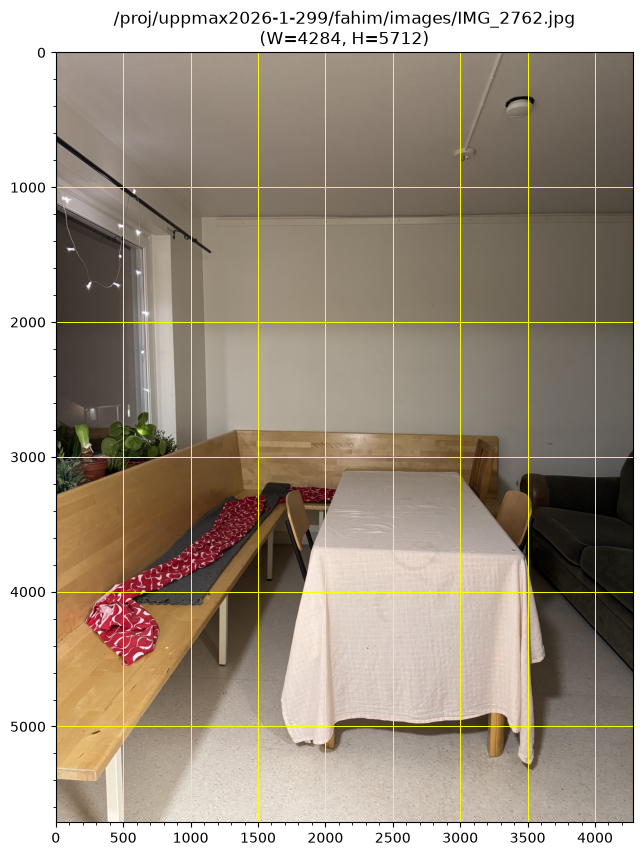

/proj/uppmax2026-1-299/fahim/images/IMG_2763.jpg -> upright size (W, H): (4284, 5712)


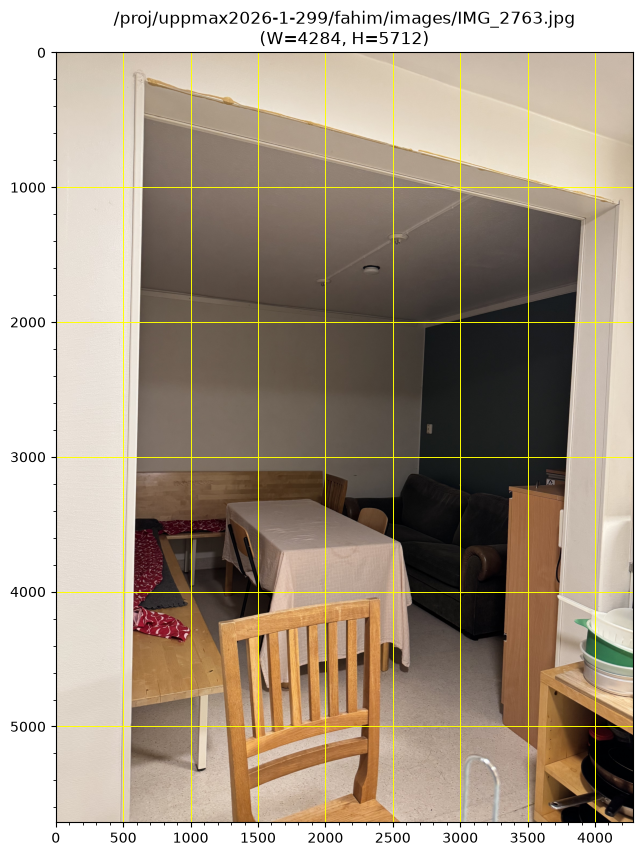

/proj/uppmax2026-1-299/fahim/images/IMG_2765.jpg -> upright size (W, H): (4284, 5712)


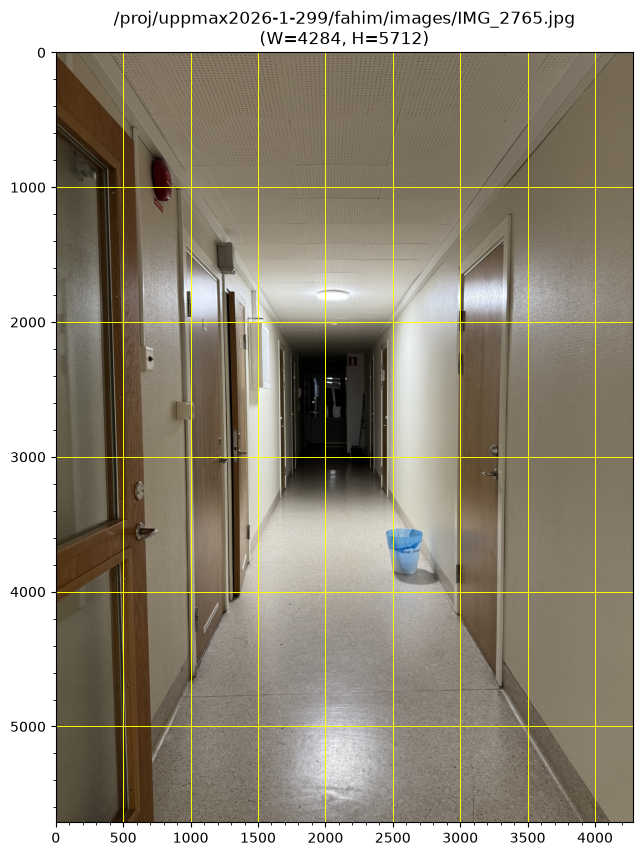

/proj/uppmax2026-1-299/fahim/images/IMG_2766.jpg -> upright size (W, H): (4284, 5712)


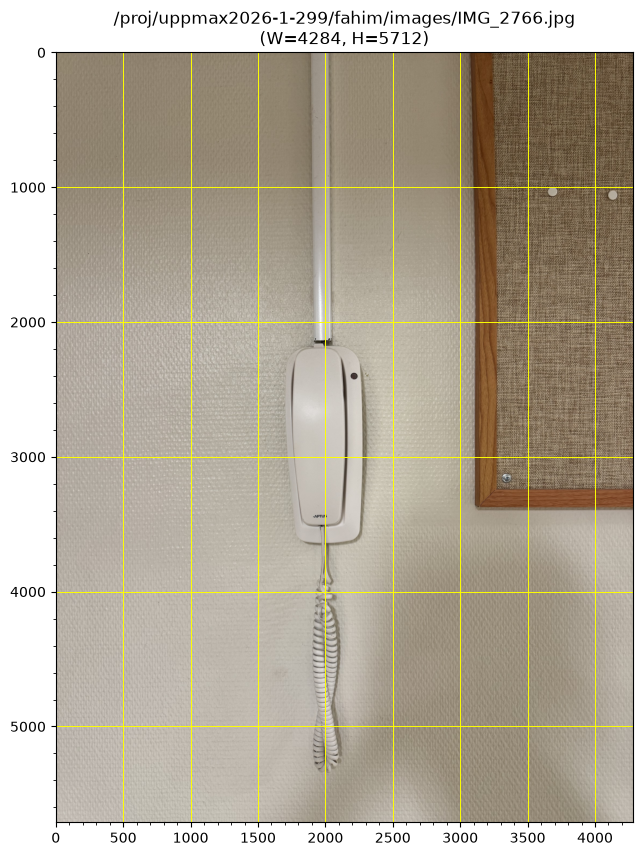

/proj/uppmax2026-1-299/fahim/images/IMG_2767.jpg -> upright size (W, H): (4284, 5712)


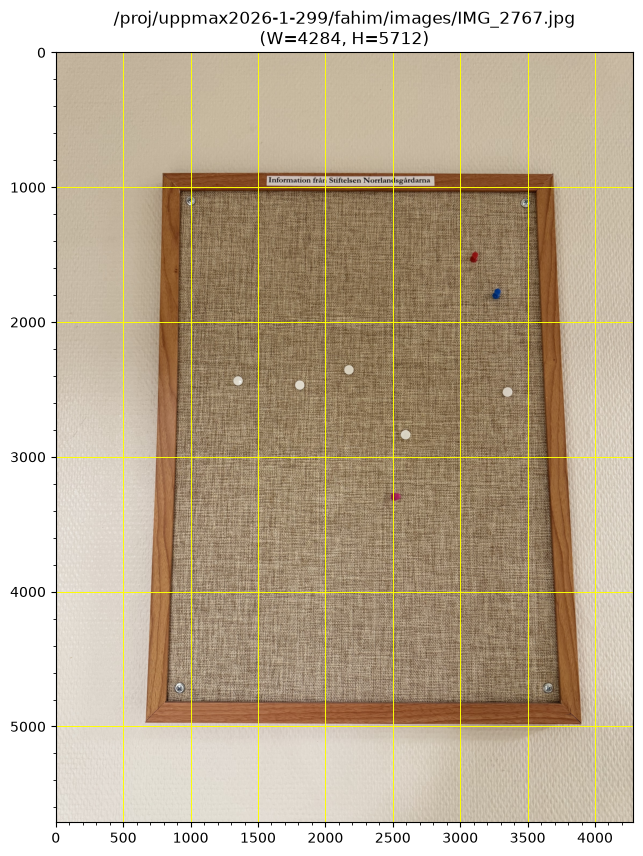

/proj/uppmax2026-1-299/fahim/images/IMG_2768.jpg -> upright size (W, H): (4284, 5712)


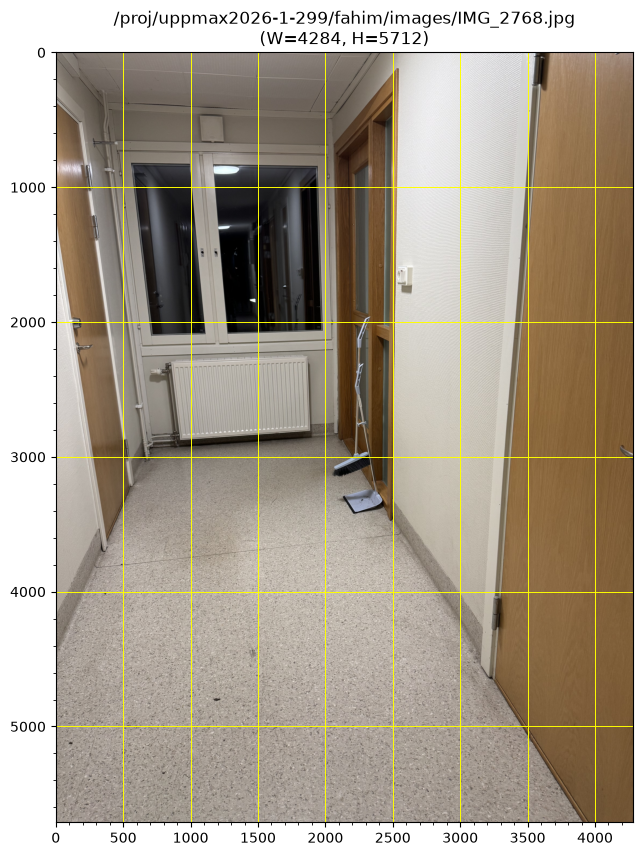

In [ ]:
import glob
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

image_paths = sorted(glob.glob("/proj/uppmax2026-1-299/fahim/images/IMG_*.jpg"))

for path in image_paths:
    im = ImageOps.exif_transpose(Image.open(path))
    im.save(path, quality=95)  # Overwrites file with physically upright pixels
    print(f"{path} -> upright size (W, H): {im.size}")

    plt.figure(figsize=(8, 10))
    plt.imshow(im)
    plt.title(f"{path}\n(W={im.size[0]}, H={im.size[1]})")
    plt.grid(True, color="yellow", linewidth=0.7)
    plt.minorticks_on()
    plt.show()

In [ ]:
def calibrate_f(width_px, dist_m, width_m): return width_px * dist_m / width_m
def backproject(u, v, z, K):
    fx, fy, cx, cy = K
    return np.array([(u - cx) * z / fx, (v - cy) * z / fy, z])
def depth_at(depth, u, v, r=5):
    return float(np.median(depth[max(0, v - r):v + r + 1, max(0, u - r):u + r + 1]))
def intrinsics(W, H, f_px, calib_w):
    s = W / calib_w
    return (f_px * s, f_px * s, W / 2, H / 2)

# F_PX, CALIB_W = 1000.0, 1920   # EDIT: focal length in pixels measured at image width CALIB_W
# MEAS = [  # EDIT: one dict per measured pair
#     dict(img="room1.jpg", p1=(320, 260), p2=(540, 300), tape=0.85),
# ]

IMG_DIR = "/proj/uppmax2026-1-299/fahim/images"

CALIB_W = 4284
F_PX = calibrate_f(width_px=650, dist_m=1.00, width_m=0.195)  # EDIT with your calibration object's px, distance, and real width
print("Calibrated F_PX:", F_PX)

MEAS = [
    # Pair 1: e.g., table width in IMG_2761.jpg
    dict(img=f"{IMG_DIR}/IMG_2761.jpg", p1=(1050, 2200), p2=(3100, 2350), tape=0.80),
    # Pair 2: e.g., chair seat height or leg length in IMG_2761.jpg
    dict(img=f"{IMG_DIR}/IMG_2761.jpg", p1=(1450, 3150), p2=(1480, 4800), tape=0.45),
    # Pair 3: e.g., corridor width or doorframe-to-bin distance in IMG_2765.jpg
    dict(img=f"{IMG_DIR}/IMG_2765.jpg", p1=(1020, 3200), p2=(2550, 3750), tape=1.85),
    # ... add 7+ more pairs across IMG_2761–IMG_2768 so you have 10+ total ...
]

def eval_room(name, depth_fn, meas=MEAS):
    rows = []
    for m in meas:
        img = Image.open(m["img"]).convert("RGB"); W, H = img.size
        d = depth_fn(img); K = intrinsics(W, H, F_PX, CALIB_W)
        P1 = backproject(*m["p1"], depth_at(d, *m["p1"]), K); P2 = backproject(*m["p2"], depth_at(d, *m["p2"]), K)
        pred = float(np.linalg.norm(P1 - P2))
        rows.append(dict(model=name, img=m["img"], tape_m=m["tape"], pred_m=pred, err_cm=100 * abs(pred - m["tape"]),
                         err_pct=100 * abs(pred - m["tape"]) / m["tape"]))
    df = pd.DataFrame(rows)
    print(name, " MAE cm: %.1f   mean err %%: %.1f" % (df.err_cm.mean(), df.err_pct.mean()))
    return df

# Backends: metric depth from DA3, and the DINOv3 head (its scale is only approximate -> see fitted scale below)
backends = {}
if "depth-anything/DA3METRIC-LARGE" in MODELS:
    backends["DA3-metric"] = lambda img: predict_da3(MODELS["depth-anything/DA3METRIC-LARGE"], [img], True)[0]
backends["dinov3-vits16+head"] = lambda img: predict_torch(MODELS["dinov3-vits16"], [img])[0]
room_df = pd.concat([eval_room(n, f) for n, f in backends.items()]) if MEAS and os.path.exists(MEAS[0]["img"]) else None
room_df

Calibrated F_PX: 3333.333333333333
DA3-metric  MAE cm: 72.6   mean err %: 90.1
dinov3-vits16+head  MAE cm: 103.8   mean err %: 139.3


,model,img,tape_m,pred_m,err_cm,err_pct
0,DA3-metric,/proj/uppmax2026-1-299/fahim/images/IMG_2761.jpg,0.80,1.994126,119.412561,149.265701
1,DA3-metric,/proj/uppmax2026-1-299/fahim/images/IMG_2761.jpg,0.45,0.853025,40.302527,89.561172
2,DA3-metric,/proj/uppmax2026-1-299/fahim/images/IMG_2765.jpg,1.85,2.429692,57.969230,31.334719
0,dinov3-vits16+head,/proj/uppmax2026-1-299/fahim/images/IMG_2761.jpg,0.80,2.676190,187.619032,234.523791
1,dinov3-vits16+head,/proj/uppmax2026-1-299/fahim/images/IMG_2761.jpg,0.45,1.141909,69.190898,153.757551
2,dinov3-vits16+head,/proj/uppmax2026-1-299/fahim/images/IMG_2765.jpg,1.85,2.395751,54.575067,29.500036


In [ ]:
# Optional: one global scale factor for a model whose metric scale is uncertain (fit on half the pairs, test on the rest!)
def fit_scale(room_df, name):
    d = room_df[room_df.model == name]
    return float(np.median(d.tape_m / d.pred_m))
# SCALE_DINOV3 = fit_scale(room_df, "dinov3-vits16+head"); print("scale:", SCALE_DINOV3)

## 6. Detection + depth + distances on a video (real-time style demo)
* Detector: YOLO (COCO weights for room objects)
* Depth backend: `dinov3-vits16+head`
* Depth is computed every `every` frames and smoothed (EMA) to reduce flicker.

In [ ]:
# import cv2
# from ultralytics import YOLO

# def box_depth(depth, x1, y1, x2, y2, frac=0.4):
#     cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
#     hw, hh = max(2, int((x2 - x1) * frac / 2)), max(2, int((y2 - y1) * frac / 2))
#     return float(np.median(depth[max(0, cy - hh):cy + hh + 1, max(0, cx - hw):cx + hw + 1]))

# def run_video(src, dst, depth_fn, det, f_px, calib_w, every=2, max_frames=None, conf=0.3, scale=1.0, show_pairs=6):
#     cap = cv2.VideoCapture(src)
#     W, H = int(cap.get(3)), int(cap.get(4)); fps_in = cap.get(5) or 30
#     wr = cv2.VideoWriter(dst, cv2.VideoWriter_fourcc(*"mp4v"), fps_in, (W, H))
#     K = intrinsics(W, H, f_px, calib_w)
#     depth, n, t_depth, t_all = None, 0, 0.0, 0.0
#     log = []
#     while True:
#         ok, frame = cap.read()
#         if not ok or (max_frames and n >= max_frames): break
#         t0 = time.time()
#         rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
#         res = det.track(frame, persist=True, verbose=False, conf=conf)[0]
#         if n % every == 0:
#             td = time.time()
#             d = depth_fn(Image.fromarray(rgb)) * scale
#             if device == "cuda": torch.cuda.synchronize()
#             t_depth += time.time() - td
#             depth = d if depth is None else 0.6 * d + 0.4 * depth
#         objs = []
#         for b in res.boxes:
#             x1, y1, x2, y2 = [int(v) for v in b.xyxy[0].tolist()]
#             z = box_depth(depth, x1, y1, x2, y2)
#             u, v = (x1 + x2) // 2, (y1 + y2) // 2
#             objs.append(dict(P=backproject(u, v, z, K), uv=(u, v), name=res.names[int(b.cls)], z=z))
#             cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 120, 0), 2)
#             cv2.putText(frame, f"{res.names[int(b.cls)]} {z:.1f}m", (x1, max(15, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
#         pairs = sorted([(np.linalg.norm(a["P"] - c["P"]), i, j) for i, a in enumerate(objs) for j, c in enumerate(objs) if i < j])[:show_pairs]
#         for dist, i, j in pairs:
#             p, q = objs[i]["uv"], objs[j]["uv"]
#             cv2.line(frame, p, q, (0, 255, 0), 1)
#             cv2.putText(frame, f"{dist:.2f}m", ((p[0] + q[0]) // 2, (p[1] + q[1]) // 2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
#             log.append(dict(frame=n, a=objs[i]["name"], b=objs[j]["name"], dist_m=float(dist)))
#         wr.write(frame); n += 1; t_all += time.time() - t0
#     cap.release(); wr.release()
#     print(f"{n} frames | pipeline {n / t_all:.1f} FPS | depth {1000 * t_depth / max(1, (n + every - 1) // every):.0f} ms per call")
#     return pd.DataFrame(log)

# VIDEO_IN = "room.mp4"          # EDIT (or your drone video)
# det = YOLO("yolo11s.pt")        # EDIT: use your own trained weights for the drone, e.g. YOLO("runs/.../best.pt")
# if os.path.exists(VIDEO_IN):
#     fast_depth = lambda img: predict_torch(MODELS["dinov3-vits16"], [img])[0]
#     log = run_video(VIDEO_IN, "out_dinov3.mp4", fast_depth, det, F_PX, CALIB_W, every=2, max_frames=600)

## 8. Experiment on webcam/iphone-cam and sample images

In [ ]:
# import cv2, time, urllib.request, numpy as np, torch
# from PIL import Image
# from ultralytics import YOLO
# from IPython.display import display, clear_output

# yolo = YOLO("yolo11s.pt")
# depth_fn = lambda img: predict_torch(MODELS["dinov3-vits16"], [img])[0]

# def fetch_frame(url):
#     with urllib.request.urlopen(url, timeout=3.0) as resp:
#         arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
#     return cv2.imdecode(arr, cv2.IMREAD_COLOR)

# def stream_live_inline(frame_url, out_path, f_px, calib_w, max_frames=200, conf=0.45):
#     first_frame = fetch_frame(frame_url)
#     H, W = first_frame.shape[:2]
#     K = intrinsics(W, H, f_px, calib_w)
#     writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), 15.0, (W, H))

#     for i in range(max_frames):
#         try:
#             frame_bgr = fetch_frame(frame_url)
#         except Exception as e:
#             print("Frame drop, retrying...", e)
#             continue

#         t0 = time.perf_counter()

#         # 1. YOLO 2D detection
#         det = yolo.predict(frame_bgr, conf=conf, verbose=False)[0]
#         boxes = det.boxes.xyxy.cpu().numpy()
#         classes = det.boxes.cls.cpu().numpy().astype(int)
#         names = det.names

#         # 2. DINOv3 metric depth
#         pil_img = Image.fromarray(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
#         with torch.amp.autocast("cuda", dtype=torch.float16):
#             depth_map = depth_fn(pil_img)

#         pts_3d, centers_2d = [], []
#         for box, cls_id in zip(boxes, classes):
#             x1, y1, x2, y2 = map(int, box)
#             u, v = (x1 + x2) // 2, (y1 + y2) // 2
#             z = depth_at(depth_map, u, v, r=5)
#             pts_3d.append(backproject(u, v, z, K))
#             centers_2d.append((u, v))

#             cv2.rectangle(frame_bgr, (x1, y1), (x2, y2), (0, 255, 120), 2)
#             cv2.circle(frame_bgr, (u, v), 5, (0, 0, 255), -1)
#             cv2.putText(frame_bgr, f"{names[cls_id]}: {z:.2f}m", (x1, max(25, y1 - 8)),
#                         cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 120), 2)

#         if len(pts_3d) >= 2:
#             dist_3d = float(np.linalg.norm(pts_3d[0] - pts_3d[1]))
#             c1, c2 = centers_2d[0], centers_2d[1]
#             mid = ((c1[0] + c2[0]) // 2, (c1[1] + c2[1]) // 2)
#             cv2.line(frame_bgr, c1, c2, (255, 200, 0), 2)
#             cv2.putText(frame_bgr, f"3D Dist: {dist_3d:.2f}m", mid,
#                         cv2.FONT_HERSHEY_SIMPLEX, 0.85, (255, 200, 0), 2)

#         dt = time.perf_counter() - t0
#         cv2.putText(frame_bgr, f"Frame {i+1}/{max_frames} | L40S: {1.0/dt:.1f} FPS", (20, 40),
#                     cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
#         writer.write(frame_bgr)

#         # Update live preview every 2nd frame
#         if i % 2 == 0:
#             small_rgb = cv2.cvtColor(cv2.resize(frame_bgr, (960, 540)), cv2.COLOR_BGR2RGB)
#             clear_output(wait=True)
#             display(Image.fromarray(small_rgb))

#     writer.release()
#     print(f"Finished! Saved {out_path}")

# stream_live_inline("http://127.0.0.1:8080/frame.jpg", "live_iphone_3d.mp4", F_PX, CALIB_W, max_frames=200)

In [ ]:
import os, torch

device = "cuda" if torch.cuda.is_available() else "cpu"

if "MODELS" not in globals():
    MODELS = {}

MODEL_KEY = "dinov3-vitb16"
CKPT_PATH = f"head_{MODEL_KEY}.pt"

if MODEL_KEY not in MODELS:
    if not os.path.exists(CKPT_PATH):
        raise FileNotFoundError(f"Checkpoint '{CKPT_PATH}' not found. Run the training cell once first.")
    
    m = DinoDepth(MODEL_KEY).to(device)
    # strict=False is required because head_*.pt only stores non-"bb." decoder weights
    state_dict = torch.load(CKPT_PATH, map_location=device, weights_only=True)
    m.load_state_dict(state_dict, strict=False)
    m.eval()
    MODELS[MODEL_KEY] = m
    print(f"Loaded cached DINOv3 depth head from {CKPT_PATH}")

depth_fn = lambda img: predict_torch(MODELS[MODEL_KEY], [img])[0]

In [ ]:
test_img = fetch_frame("http://127.0.0.1:8080/frame.jpg")
print("Connected! Frame shape:", test_img.shape)

Connected! Frame shape: (1080, 1920, 3)


In [ ]:
import cv2, time, urllib.request, numpy as np, torch
from PIL import Image
from ultralytics import YOLO
from IPython.display import display, clear_output

yolo = YOLO("yolo11s.pt")
depth_fn = lambda img: predict_torch(MODELS[MODEL_KEY], [img])[0]

# Optional: add any standard classroom items you want to verify live (in meters)
KNOWN_WIDTHS = {
    "bottle": 0.085,
    "cup": 0.085,
    "cell phone": 0.071,
    "laptop": 0.312,
    "book": 0.297,
}

# Distinct high-contrast BGR colors for multiple objects
PALETTE = [
    (0, 230, 118),   # Emerald Green
    (255, 196, 0),   # Cyan-Blue
    (0, 176, 255),   # Amber-Orange
    (234, 128, 252), # Violet
    (118, 255, 3),   # Lime
]

def draw_label_pill(img, text, org, bg_color=(20, 20, 20), txt_color=(255, 255, 255), scale=0.65, thickness=2):
    """Draws readable text over a solid background pill for projector visibility."""
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), baseline = cv2.getTextSize(text, font, scale, thickness)
    x, y = org
    x = max(5, min(x, img.shape[1] - tw - 10))
    y = max(th + 10, min(y, img.shape[0] - 10))
    cv2.rectangle(img, (x - 4, y - th - 6), (x + tw + 6, y + baseline + 4), bg_color, -1)
    cv2.putText(img, text, (x, y), font, scale, txt_color, thickness, cv2.LINE_AA)

def fetch_frame(url):
    with urllib.request.urlopen(url, timeout=3.0) as resp:
        arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)

def run_presentation_demo(
    frame_url="http://127.0.0.1:8080/frame.jpg",
    out_path="presentation_demo.mp4",
    f_px=3300.0,          # Replace with your calibrated F_PX for the live camera
    calib_w=4284,         # Replace with your CALIB_W for the live camera orientation
    scale_factor=0.35,    # Replace with your calibrated scale_factor for MODEL_KEY
    max_frames=600,
    max_objects=4,
    conf=0.45,
    ema_alpha=0.45        # Smoothing factor (0.3-0.5 removes hand tremor jitter)
):
    first_frame = fetch_frame(frame_url)
    H, W = first_frame.shape[:2]
    K = intrinsics(W, H, f_px, calib_w)
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), 15.0, (W, H))

    smooth_z = {}
    smooth_dist = {}

    try:
        for i in range(max_frames):
            try:
                frame_bgr = fetch_frame(frame_url)
            except Exception:
                continue

            t0 = time.perf_counter()

            # 1. YOLO11 2D Object Detection
            det = yolo.predict(frame_bgr, conf=conf, verbose=False)[0]
            boxes = det.boxes.xyxy.cpu().numpy()
            confs = det.boxes.conf.cpu().numpy()
            classes = det.boxes.cls.cpu().numpy().astype(int)
            names = det.names

            # 2. DINOv3 Metric Depth Prediction
            pil_img = Image.fromarray(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
            with torch.amp.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
                depth_map = depth_fn(pil_img) * scale_factor

            # Keep top N highest-confidence detections, then sort left-to-right so lines don't cross
            detections = [(box, c_score, names[cls_id]) for box, c_score, cls_id in zip(boxes, confs, classes)]
            detections.sort(key=lambda d: d[1], reverse=True)
            detections = detections[:max_objects]
            detections.sort(key=lambda d: (d[0][0] + d[0][2]) / 2.0)

            objects_3d = []

            for idx, (box, c_score, cls_name) in enumerate(detections):
                color = PALETTE[idx % len(PALETTE)]
                x1, y1, x2, y2 = map(int, box)
                u, v = (x1 + x2) // 2, (y1 + y2) // 2

                # Raw depth + EMA temporal smoothing
                raw_z = depth_at(depth_map, u, v, r=5)
                key = f"{cls_name}_{idx}"
                z = ema_alpha * raw_z + (1 - ema_alpha) * smooth_z.get(key, raw_z)
                smooth_z[key] = z

                # 3D center point & physical 3D width of the object
                P_center = backproject(u, v, z, K)
                pad = max(6, int((x2 - x1) * 0.05))
                P_left = backproject(x1 + pad, v, depth_at(depth_map, x1 + pad, v, r=4), K)
                P_right = backproject(x2 - pad, v, depth_at(depth_map, x2 - pad, v, r=4), K)
                obj_w = float(np.linalg.norm(P_right - P_left))

                objects_3d.append((cls_name, (u, v), P_center, color))

                # Draw bounding box & center point
                cv2.rectangle(frame_bgr, (x1, y1), (x2, y2), color, 3)
                cv2.circle(frame_bgr, (u, v), 7, color, -1)
                cv2.circle(frame_bgr, (u, v), 9, (20, 20, 20), 2)

                # Build clean label (shows GT error automatically if object is in KNOWN_WIDTHS)
                if cls_name in KNOWN_WIDTHS:
                    gt_w = KNOWN_WIDTHS[cls_name]
                    err_cm = abs(obj_w - gt_w) * 100.0
                    lbl = f"{cls_name.upper()} | Z:{z:.2f}m | W:{obj_w:.2f}m (Err:{err_cm:.1f}cm)"
                else:
                    lbl = f"{cls_name.upper()} | Z:{z:.2f}m | W:{obj_w:.2f}m"

                draw_label_pill(frame_bgr, lbl, (x1, y1 - 8), bg_color=(20, 20, 20), txt_color=color, scale=0.6)

            # 3. Pairwise 3D Euclidean Distances between adjacent objects (left-to-right chain)
            for j in range(len(objects_3d) - 1):
                name_a, c_a, P_a, _ = objects_3d[j]
                name_b, c_b, P_b, _ = objects_3d[j + 1]

                raw_dist = float(np.linalg.norm(P_a - P_b))
                pair_key = f"{j}_{j+1}"
                dist_3d = ema_alpha * raw_dist + (1 - ema_alpha) * smooth_dist.get(pair_key, raw_dist)
                smooth_dist[pair_key] = dist_3d

                cv2.line(frame_bgr, c_a, c_b, (255, 255, 255), 4)
                cv2.line(frame_bgr, c_a, c_b, (0, 140, 255), 2)
                mid = ((c_a[0] + c_b[0]) // 2 - 45, (c_a[1] + c_b[1]) // 2)
                draw_label_pill(frame_bgr, f"{dist_3d:.2f} m", mid, bg_color=(0, 100, 220), txt_color=(255, 255, 255), scale=0.7)

            # 4. Picture-in-Picture (PiP) Colorized DINOv3 Depth Map in bottom-right corner
            d_norm = cv2.normalize(depth_map, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
            d_color = cv2.applyColorMap(255 - d_norm, cv2.COLORMAP_INFERNO)  # Warm = close, Dark = far
            pip_w, pip_h = W // 4, H // 4
            pip = cv2.resize(d_color, (pip_w, pip_h))
            cv2.rectangle(pip, (0, 0), (pip_w - 1, pip_h - 1), (255, 255, 255), 2)
            frame_bgr[H - pip_h - 20 : H - 20, W - pip_w - 20 : W - 20] = pip
            draw_label_pill(frame_bgr, f"{MODEL_KEY} Depth Map", (W - pip_w - 15, H - pip_h - 26), scale=0.5)

            # 5. Top Status Banner
            dt = time.perf_counter() - t0
            hud = f"LIVE 3D SPATIAL VISION (YOLOv11 + {MODEL_KEY}) | Objects: {len(objects_3d)} | GPU: {1.0/dt:.1f} FPS"
            draw_label_pill(frame_bgr, hud, (20, 38), bg_color=(15, 15, 15), txt_color=(255, 255, 255), scale=0.72)

            writer.write(frame_bgr)

            # Update browser preview every 2nd frame for smooth playback
            if i % 2 == 0:
                preview = cv2.cvtColor(cv2.resize(frame_bgr, (1024, 576)), cv2.COLOR_BGR2RGB)
                clear_output(wait=True)
                display(Image.fromarray(preview))
    finally:
        # Ensures presentation_demo.mp4 is properly finalized even if you interrupt the cell early
        writer.release()
        print(f"Saved presentation recording to {out_path}")

# Run the live presentation demo:
run_presentation_demo(
    f_px=F_PX,
    calib_w=CALIB_W,
    scale_factor=0.35,   # <-- Replace with your calibrated scale_factor from eval_room!
    max_frames=200       # ~30-40 seconds of live demo
)

### On Images

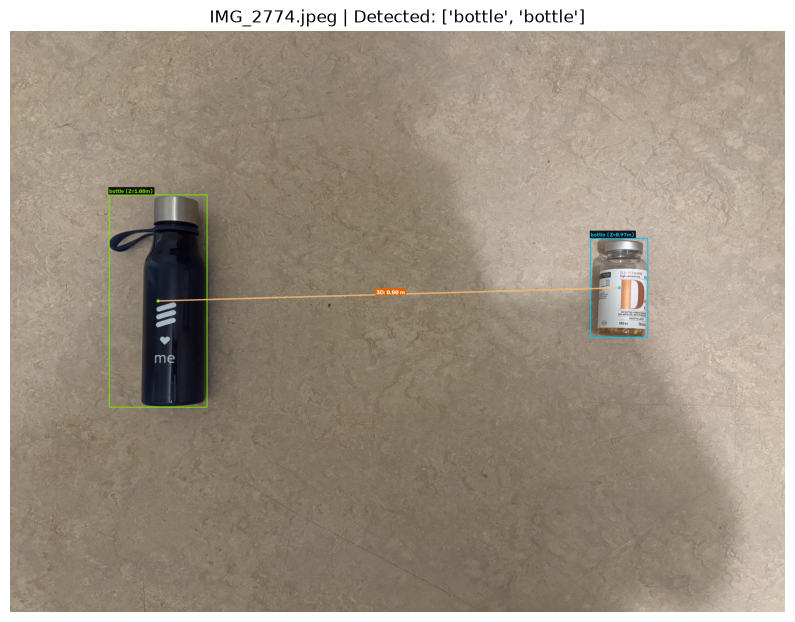

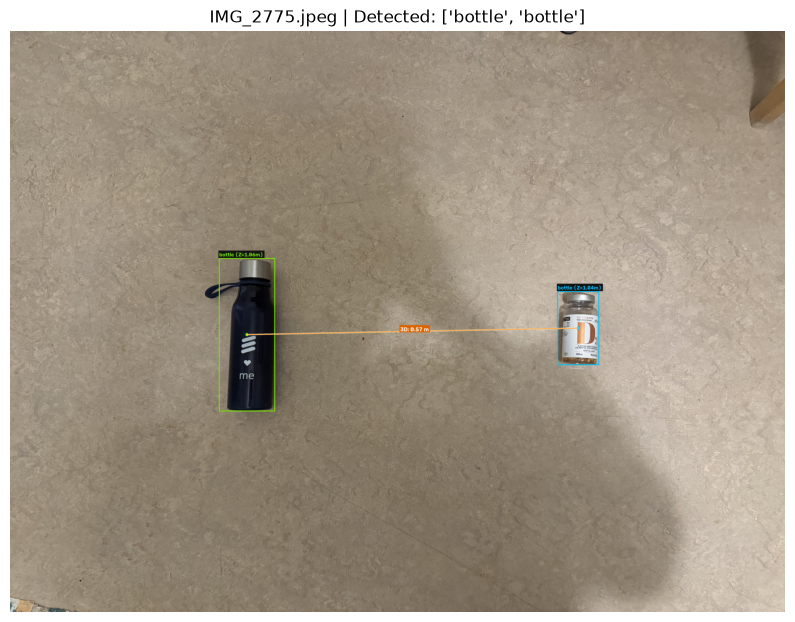

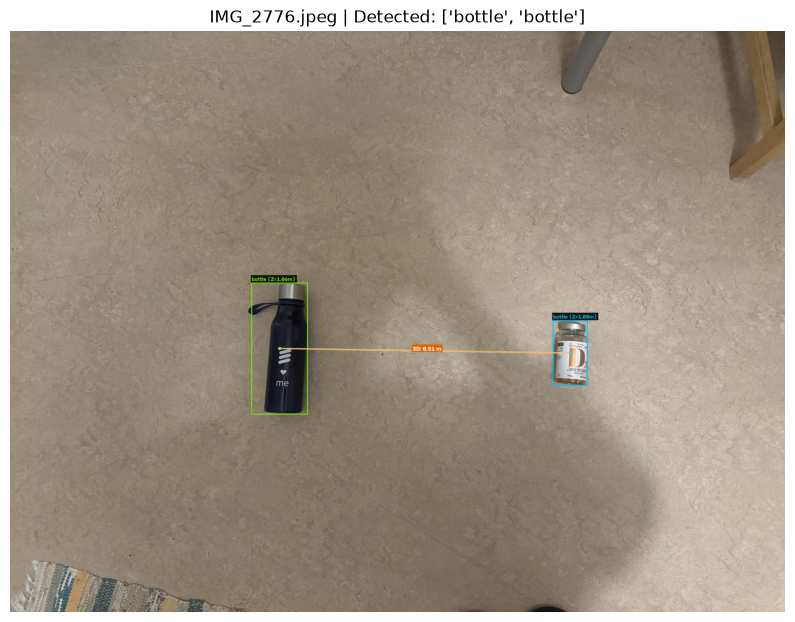

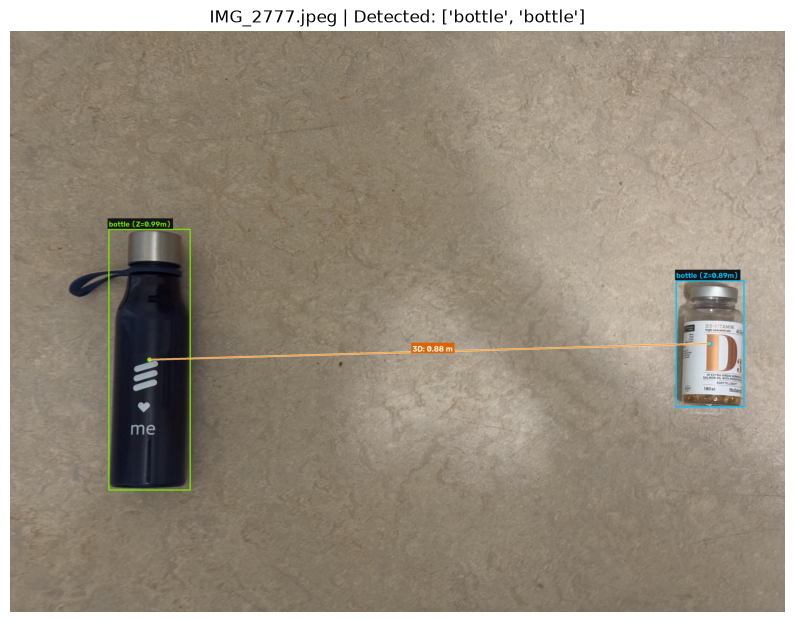

,image,detected,pred_3d_m,ground_truth_m,abs_err_cm,err_pct
0,IMG_2774.jpeg,"bottle, bottle",0.796,0.5,29.60,59.2
1,IMG_2775.jpeg,"bottle, bottle",0.574,0.5,7.44,14.9
2,IMG_2776.jpeg,"bottle, bottle",0.515,0.5,1.49,3.0
3,IMG_2777.jpeg,"bottle, bottle",0.878,0.5,37.85,75.7


Overall MAE: 19.09 cm | Mean Error %: 38.2%


In [ ]:
import glob, os, cv2, numpy as np, pandas as pd, torch
from PIL import Image, ImageOps
from ultralytics import YOLO
import matplotlib.pyplot as plt

yolo = YOLO("yolo11s.pt")
depth_fn = lambda img: predict_torch(MODELS["dinov3-vits16"], [img])[0]

PALETTE = [(0, 230, 118), (255, 196, 0), (0, 176, 255), (234, 128, 252)]

def draw_pill(img, text, org, bg=(20, 20, 20), fg=(255, 255, 255), scale=1.1, thick=2):
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), base = cv2.getTextSize(text, font, scale, thick)
    x, y = max(10, min(org[0], img.shape[1] - tw - 15)), max(th + 15, min(org[1], img.shape[0] - 15))
    cv2.rectangle(img, (x - 6, y - th - 8), (x + tw + 8, y + base + 6), bg, -1)
    cv2.putText(img, text, (x, y), font, scale, fg, thick, cv2.LINE_AA)

# Match exact filenames in /proj/uppmax2026-1-299/fahim/real_images
GROUND_TRUTH = {
    "IMG_2774.jpeg": 0.50,
    "IMG_2775.jpeg": 0.50,
    "IMG_2776.jpeg": 0.50,
    "IMG_2777.jpeg": 0.50,
}

def evaluate_still_images(img_dir, f_px, calib_w, scale_factor=0.57, target_class="bottle", conf=0.25):
    paths = sorted(glob.glob(os.path.join(img_dir, "*.jp*g")))
    if not paths:
        raise FileNotFoundError(f"No .jpg/.jpeg images found in {img_dir}")

    records = []
    for path in paths:
        fname = os.path.basename(path)
        pil_img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
        W, H = pil_img.size
        K = intrinsics(W, H, f_px, calib_w)

        frame_bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
        det = yolo.predict(frame_bgr, conf=conf, verbose=False)[0]
        boxes = det.boxes.xyxy.cpu().numpy()
        confs = det.boxes.conf.cpu().numpy()
        classes = det.boxes.cls.cpu().numpy().astype(int)
        names = det.names

        with torch.amp.autocast("cuda", dtype=torch.float16):
            depth_map = depth_fn(pil_img) * scale_factor

        # Filter to target_class (if set), keep top 2 by confidence, then sort left-to-right
        dets = [
            (b, c, names[cid]) for b, c, cid in zip(boxes, confs, classes)
            if (target_class is None or names[cid] == target_class)
        ]
        dets.sort(key=lambda d: d[1], reverse=True)
        dets = sorted(dets[:2], key=lambda d: (d[0][0] + d[0][2]) / 2.0)

        objs_3d = []
        for idx, (box, c_score, cls_name) in enumerate(dets):
            color = PALETTE[idx % len(PALETTE)]
            x1, y1, x2, y2 = map(int, box)
            u, v = (x1 + x2) // 2, (y1 + y2) // 2
            z = depth_at(depth_map, u, v, r=7)
            P = backproject(u, v, z, K)
            objs_3d.append((cls_name, (u, v), P))

            cv2.rectangle(frame_bgr, (x1, y1), (x2, y2), color, 6)
            cv2.circle(frame_bgr, (u, v), 12, color, -1)
            draw_pill(frame_bgr, f"{cls_name} (Z={z:.2f}m)", (x1, y1 - 14), fg=color, scale=1.3, thick=3)

        pair_dists = []
        for j in range(len(objs_3d) - 1):
            name_a, c_a, P_a = objs_3d[j]
            name_b, c_b, P_b = objs_3d[j + 1]
            d_3d = float(np.linalg.norm(P_a - P_b))
            pair_dists.append(d_3d)

            cv2.line(frame_bgr, c_a, c_b, (255, 255, 255), 8)
            cv2.line(frame_bgr, c_a, c_b, (0, 140, 255), 4)
            mid = ((c_a[0] + c_b[0]) // 2 - 90, (c_a[1] + c_b[1]) // 2)
            draw_pill(frame_bgr, f"3D: {d_3d:.2f} m", mid, bg=(0, 100, 220), scale=1.4, thick=3)

        pred_d = pair_dists[0] if pair_dists else np.nan
        gt_d = GROUND_TRUTH.get(fname, np.nan)
        err_cm = abs(pred_d - gt_d) * 100.0 if not np.isnan(pred_d) and not np.isnan(gt_d) else np.nan
        err_pct = (abs(pred_d - gt_d) / gt_d) * 100.0 if not np.isnan(err_cm) else np.nan

        records.append({
            "image": fname,
            "detected": ", ".join([o[0] for o in objs_3d]),
            "pred_3d_m": round(pred_d, 3) if not np.isnan(pred_d) else None,
            "ground_truth_m": gt_d if not np.isnan(gt_d) else None,
            "abs_err_cm": round(err_cm, 2) if not np.isnan(err_cm) else None,
            "err_pct": round(err_pct, 1) if not np.isnan(err_pct) else None,
        })

        plt.figure(figsize=(10, 8))
        plt.imshow(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
        plt.title(f"{fname} | Detected: {[o[0] for o in objs_3d]}")
        plt.axis("off")
        plt.show()

    df = pd.DataFrame(records)
    display(df)
    if df["abs_err_cm"].notna().any():
        print(f"Overall MAE: {df['abs_err_cm'].mean():.2f} cm | Mean Error %: {df['err_pct'].mean():.1f}%")
    return df

df_toys = evaluate_still_images(
    img_dir="/proj/uppmax2026-1-299/fahim/real_images",
    f_px=F_PX,
    calib_w=CALIB_W,
    scale_factor=0.57,
    target_class="bottle"  # Set to None when evaluating mixed multi-object scenes
)

In [ ]:
import os

IMG_DIR = "../new_images" if os.path.exists("../new_images") else "new_images"
print("Using IMG_DIR:", os.path.abspath(IMG_DIR))
print("Files:", sorted(os.listdir(IMG_DIR)))

Using IMG_DIR: /gorilla/proj/uppmax2026-1-299/fahim/new_images
Files: ['.ipynb_checkpoints', 'IMG_2794.jpeg', 'IMG_2795.jpeg', 'IMG_2796.jpeg', 'IMG_2797.jpeg', 'IMG_2798.jpeg', 'IMG_2799.jpeg', 'IMG_2800.jpeg', 'IMG_2801.jpeg', 'IMG_2802.jpeg', 'IMG_2803.jpeg', 'IMG_2804.jpeg', 'IMG_2805.jpeg', 'IMG_2806.jpeg', 'IMG_2807.jpeg', 'IMG_2808.jpeg', 'IMG_2809.jpeg', 'IMG_2810.jpeg', 'IMG_2811.jpeg']


DA3Metric-Large      | MAE: 4.03 cm | Mean Err: 13.0%


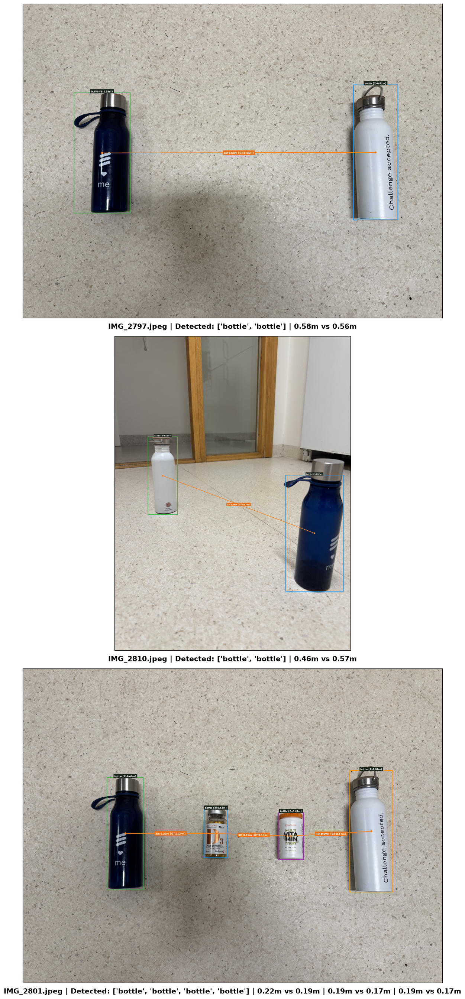

dinov3-vitb16+head   | MAE: 12.67 cm | Mean Err: 40.8%


,model,image,pair,pred_3d_m,gt_m,abs_err_cm,err_pct
0,DA3Metric-Large,IMG_2797.jpeg,Obj 1 -> 2,0.575,0.56,1.55,2.8
1,DA3Metric-Large,IMG_2810.jpeg,Obj 1 -> 2,0.461,0.57,10.90,19.1
2,DA3Metric-Large,IMG_2801.jpeg,Obj 1 -> 2,0.224,0.19,3.41,18.0
3,DA3Metric-Large,IMG_2801.jpeg,Obj 2 -> 3,0.193,0.17,2.28,13.4
4,DA3Metric-Large,IMG_2801.jpeg,Obj 3 -> 4,0.190,0.17,2.02,11.9
5,dinov3-vitb16+head,IMG_2797.jpeg,Obj 1 -> 2,0.767,0.56,20.66,36.9
6,dinov3-vitb16+head,IMG_2810.jpeg,Obj 1 -> 2,0.759,0.57,18.87,33.1
7,dinov3-vitb16+head,IMG_2801.jpeg,Obj 1 -> 2,0.289,0.19,9.92,52.2
8,dinov3-vitb16+head,IMG_2801.jpeg,Obj 2 -> 3,0.255,0.17,8.53,50.2
9,dinov3-vitb16+head,IMG_2801.jpeg,Obj 3 -> 4,0.224,0.17,5.38,31.7


In [ ]:
import os, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

IMG_DIR = "../new_images" if os.path.exists("../new_images") else "new_images"

NEW_TESTS = [
    ("IMG_2797.jpeg", [0.56]),               # Matches IMG_2795.jpeg (56 cm Measure GT)
    ("IMG_2810.jpeg", [0.57]),               # Angled depth-offset pair (57 cm Measure GT)
    ("IMG_2801.jpeg", [0.19, 0.17, 0.17]),   # Matches IMG_2800.jpeg (19 / 17 / 17 cm Measure GT)
]

def draw_label_pill(img, text, x, y, bg_color=(20, 20, 20), text_color=(255, 255, 255), scale=1.4, thickness=3):
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thickness)
    pad = 12
    x1, y1 = max(0, x - tw // 2 - pad), max(0, y - th // 2 - pad)
    x2, y2 = min(img.shape[1], x + tw // 2 + pad), min(img.shape[0], y + th // 2 + pad)
    cv2.rectangle(img, (x1, y1), (x2, y2), bg_color, -1)
    cv2.putText(img, text, (x1 + pad, y2 - pad), cv2.FONT_HERSHEY_SIMPLEX, scale, text_color, thickness, cv2.LINE_AA)

def eval_multi_bottle_images(model_label, depth_fn, scale_factor=1.0, calib_w=4284, calib_h=5712, show_preview=True):
    rows = []
    previews = []

    for fname, gt_list in NEW_TESTS:
        path = os.path.join(IMG_DIR, fname)
        img = ImageOps.exif_transpose(Image.open(path).convert("RGB"))
        W, H = img.size
        K = intrinsics_safe(W, H, F_PX, calib_w, calib_h)
        vis = np.array(img).copy()

        det = yolo.predict(vis[:, :, ::-1], conf=0.08, imgsz=1280, verbose=False)[0]
        IGNORE = {"person", "dining table", "bed", "couch", "chair", "bench", "floor"}
        bottles = [
            (box, float(c), det.names[cls_id])
            for box, c, cls_id in zip(det.boxes.xyxy.cpu().numpy(),
                                      det.boxes.conf.cpu().numpy(),
                                      det.boxes.cls.cpu().numpy().astype(int))
            if det.names[cls_id] not in IGNORE
        ]
        bottles.sort(key=lambda x: x[1], reverse=True)
        bottles = sorted(bottles[: len(gt_list) + 1], key=lambda x: (x[0][0] + x[0][2]) / 2.0)

        dmap = depth_fn(img) * scale_factor
        pts_3d, centers, det_labels = [], [], []
        box_colors = [(76, 175, 80), (33, 150, 243), (156, 39, 176), (255, 152, 0)]

        for idx, (box, _, lbl) in enumerate(bottles):
            x1, y1, x2, y2 = map(int, box)
            u, v = (x1 + x2) // 2, (y1 + y2) // 2
            z = box_depth(dmap, box, q=35)
            pts_3d.append(backproject(u, v, z, K))
            centers.append((u, v))
            det_labels.append(lbl)

            col = box_colors[idx % len(box_colors)]
            cv2.rectangle(vis, (x1, y1), (x2, y2), col, 8)
            draw_label_pill(vis, f"{lbl} (Z={z:.2f}m)", x1 + (x2 - x1) // 2, max(35, y1 - 22), bg_color=(25, 35, 25), scale=1.2, thickness=3)

        pair_summaries = []
        if len(bottles) < len(gt_list) + 1:
            print(f"[{model_label}] {fname}: expected {len(gt_list)+1} objects, found {len(bottles)}")
            status = f"Found {len(bottles)}/{len(gt_list)+1} objects"
        else:
            for pair_idx, gt_m in enumerate(gt_list):
                pred_m = float(np.linalg.norm(pts_3d[pair_idx] - pts_3d[pair_idx + 1]))
                err_cm = abs(pred_m - gt_m) * 100.0
                rows.append({
                    "model": model_label,
                    "image": fname,
                    "pair": f"Obj {pair_idx+1} -> {pair_idx+2}",
                    "pred_3d_m": round(pred_m, 3),
                    "gt_m": gt_m,
                    "abs_err_cm": round(err_cm, 2),
                    "err_pct": round(100.0 * abs(pred_m - gt_m) / gt_m, 1),
                })

                c1, c2 = centers[pair_idx], centers[pair_idx + 1]
                cv2.line(vis, c1, c2, (245, 130, 32), 8)
                cv2.circle(vis, c1, 14, (245, 130, 32), -1)
                cv2.circle(vis, c2, 14, (245, 130, 32), -1)
                mid_x, mid_y = (c1[0] + c2[0]) // 2, (c1[1] + c2[1]) // 2
                draw_label_pill(vis, f"3D: {pred_m:.2f}m (GT:{gt_m:.2f}m)", mid_x, mid_y, bg_color=(230, 110, 20), scale=1.3, thickness=3)
                pair_summaries.append(f"{pred_m:.2f}m vs {gt_m:.2f}m")
            status = " | ".join(pair_summaries)

        # Save the two slide showcase images to disk
        if show_preview:
            if fname == "IMG_2797.jpeg":
                cv2.imwrite("pred_2797.jpg", cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
            elif fname == "IMG_2801.jpeg":
                cv2.imwrite("pred_2801.jpg", cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))

        previews.append((vis, f"{fname} | Detected: {det_labels} | {status}"))

    df_out = pd.DataFrame(rows)
    if not df_out.empty:
        print(f"{model_label:20s} | MAE: {df_out.abs_err_cm.mean():.2f} cm | Mean Err: {df_out.err_pct.mean():.1f}%")

    if show_preview and previews:
        fig, axes = plt.subplots(len(previews), 1, figsize=(12, 9 * len(previews)))
        if len(previews) == 1:
            axes = [axes]
        for ax, (vis_img, caption) in zip(axes, previews):
            ax.imshow(vis_img)
            ax.set_xlabel(caption, fontsize=14, fontweight="bold", labelpad=10)
            ax.set_xticks([])
            ax.set_yticks([])
        plt.tight_layout()
        plt.show()

    return df_out

res_da3 = eval_multi_bottle_images(
    "DA3Metric-Large",
    lambda im: predict_da3_calibrated(MODELS["depth-anything/DA3METRIC-LARGE"], [im])[0],
    scale_factor=1.0,
    show_preview=True
)
res_dino = eval_multi_bottle_images(
    "dinov3-vitb16+head",
    lambda im: predict_torch(MODELS["dinov3-vitb16"], [im])[0],
    scale_factor=SCALE_FACTORS["dinov3-vitb16"],
    show_preview=False
)
pd.concat([res_da3, res_dino], ignore_index=True)

In [ ]:
def predict_da3_calibrated(model, imgs, f_px=F_PX, calib_w=5712):
    with contextlib.redirect_stdout(io.StringIO()):
        pred = model.inference(list(imgs))
    d = torch.from_numpy(np.asarray(pred.depth, dtype=np.float32))[:, None]
    if pred.intrinsics is not None:
        f = torch.from_numpy(np.asarray(pred.intrinsics, dtype=np.float32))[:, 0, 0].view(-1, 1, 1, 1)
    else:
        # Scale camera F_PX to DA3's internal 504px long-side resolution
        f = (f_px / calib_w) * 504.0
    d = d * f / 300.0
    return [F.interpolate(d[i:i + 1], size=(im.size[1], im.size[0]), mode="bilinear", align_corners=False)[0, 0].numpy()
            for i, im in enumerate(imgs)]

# 1. Fit each DINO head's exact scale_factor on ONE reference image (IMG_2775.jpeg)
CAL_IMG = "IMG_2775.jpeg"
SCALE_FACTORS = {}
for k in ["dinov3-vits16", "dinov3-vitb16", "dinov2-base"]:
    if k in MODELS:
        tmp = eval_bottle_pairs(k, lambda im, kk=k: predict_torch(MODELS[kk], [im])[0], scale_factor=1.0)
        raw_pred = tmp.loc[tmp["image"] == CAL_IMG, "pred_3d_m"].values[0]
        SCALE_FACTORS[k] = round(0.50 / raw_pred, 4)

print("Fitted SCALE_FACTORS from IMG_2775:", SCALE_FACTORS)

# 2. Evaluate all models cleanly
all_dfs = []
for k, sf in SCALE_FACTORS.items():
    all_dfs.append(eval_bottle_pairs(f"{k}+head", lambda im, kk=k: predict_torch(MODELS[kk], [im])[0], scale_factor=sf))

if "depth-anything/DA3METRIC-LARGE" in MODELS:
    all_dfs.append(eval_bottle_pairs(
        "DA3Metric-Large",
        lambda im: predict_da3_calibrated(MODELS["depth-anything/DA3METRIC-LARGE"], [im])[0],
        scale_factor=1.0
    ))

comparison_df = pd.concat(all_dfs, ignore_index=True)
comparison_df

dinov3-vits16        | MAE: 110.44 cm | Mean Err: 220.9%
dinov3-vitb16        | MAE: 129.37 cm | Mean Err: 258.8%
dinov2-base          | MAE: 142.30 cm | Mean Err: 284.6%
Fitted SCALE_FACTORS from IMG_2775: {'dinov3-vits16': np.float64(0.3729), 'dinov3-vitb16': np.float64(0.3695), 'dinov2-base': np.float64(0.3499)}
dinov3-vits16+head   | MAE: 12.39 cm | Mean Err: 24.8%
dinov3-vitb16+head   | MAE: 17.85 cm | Mean Err: 35.7%
dinov2-base+head     | MAE: 20.99 cm | Mean Err: 42.0%
DA3Metric-Large      | MAE: 4.16 cm | Mean Err: 8.3%


,model,image,res,pred_3d_m,gt_m,abs_err_cm,err_pct
0,dinov3-vits16+head,IMG_2774.jpeg,5712x4284,0.684,0.5,18.41,36.8
1,dinov3-vits16+head,IMG_2775.jpeg,5712x4284,0.500,0.5,0.01,0.0
2,dinov3-vits16+head,IMG_2776.jpeg,5712x4284,0.449,0.5,5.13,10.3
3,dinov3-vits16+head,IMG_2777.jpeg,4032x3024,0.760,0.5,26.03,52.1
4,dinov3-vitb16+head,IMG_2774.jpeg,5712x4284,0.778,0.5,27.76,55.5
5,dinov3-vitb16+head,IMG_2775.jpeg,5712x4284,0.500,0.5,0.02,0.0
6,dinov3-vitb16+head,IMG_2776.jpeg,5712x4284,0.469,0.5,3.12,6.2
7,dinov3-vitb16+head,IMG_2777.jpeg,4032x3024,0.905,0.5,40.49,81.0
8,dinov2-base+head,IMG_2774.jpeg,5712x4284,0.817,0.5,31.70,63.4
9,dinov2-base+head,IMG_2775.jpeg,5712x4284,0.500,0.5,0.00,0.0
